# Fig 2A — Per-cancer-type Correlation: Axis Scores vs TMB

Grouped bar chart of bootstrapped Pearson r (axis score vs log₁₀(TMB)) per cancer type,
with 95% bootstrap CIs. Cancer types sorted by TMB axis score r (descending).

Reads from pre-computed `results/tables/score_corr_per_type_summary.csv`.
To regenerate that CSV, run `fig2a_bootstrap_compute.ipynb`.

PDF export uses TrueType fonts so text remains editable in Adobe Illustrator/InDesign.

In [28]:
import os
import socket

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# Editable text in Adobe Illustrator / InDesign (TrueType, not outlines)
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

In [29]:
hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

DATA_PATH = f"{BASE_DIR}/results/tables/score_corr_per_type_summary.csv"
OUT_DIR   = f"{BASE_DIR}/results/figures/main/fig2"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"OUT_DIR: {OUT_DIR}")

OUT_DIR: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/results/figures/main/fig2


In [30]:
bs_corr_df = pd.read_csv(DATA_PATH)
bs_corr_df.head()

,cancer_type,score,r,ci_low,ci_high,p_value,n,fdr,score_label
0,ACC,TMB_axis_score,0.495984,0.309840,0.657334,0.001998,79,0.003761,TMB axis
1,ACC,pqc_axis_score,0.088999,-0.125977,0.278732,0.387612,79,0.442986,PQC axis
2,ACC,non_pqc_axis_score,0.506329,0.305232,0.654230,0.001998,79,0.003761,Non-PQC axis
3,BLCA,TMB_axis_score,0.372222,0.272249,0.462723,0.001998,406,0.003761,TMB axis
4,BLCA,pqc_axis_score,0.218927,0.122226,0.310379,0.001998,406,0.007104,PQC axis


## Plot config

Edit values here to adjust aesthetics globally.

In [31]:
import sys

sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS

SCORES = ["TMB_axis_score", "pqc_axis_score", "non_pqc_axis_score"]

PALETTE = {
    "TMB_axis_score":     "#0072B2",  # blue
    "pqc_axis_score":     "#D55E00",  # vermillion
    "non_pqc_axis_score": "#009E73",  # teal
}

SCORE_LABELS = {
    "TMB_axis_score":     "TMB axis",
    "pqc_axis_score":     "PQC axis",
    "non_pqc_axis_score": "Non-PQC axis",
}

CI_COLOR = COLORS["light_gray"]

FIGSIZE   = (12, 6)
BAR_WIDTH = 0.25
CAP_SIZE  = 3

# Fixed margins — keeps axes area identical regardless of tick label widths
MARGINS = dict(left=0.07, right=0.98, bottom=0.28, top=0.96)

## Plot function

In [32]:
def plot_corr_barplot(df, filename):
    """Grouped bar chart of per-cancer-type r, sorted by TMB axis score."""
    order = (
        df[df["score"] == "TMB_axis_score"]
        .sort_values("r", ascending=False)["cancer_type"]
        .values
    )
    x = np.arange(len(order))

    fig, ax = plt.subplots(figsize=FIGSIZE)
    fig.subplots_adjust(**MARGINS)

    for i, score in enumerate(SCORES):
        df_sub = (
            df[df["score"] == score]
            .set_index("cancer_type")
            .reindex(order)
        )
        y    = df_sub["r"].values
        yerr = [y - df_sub["ci_low"].values, df_sub["ci_high"].values - y]

        ax.bar(
            x + (i - 1) * BAR_WIDTH,
            y,
            width=BAR_WIDTH,
            label=SCORE_LABELS[score],
            color=PALETTE[score],
            edgecolor="black",
            yerr=yerr,
            capsize=CAP_SIZE,
            error_kw=dict(linewidth=1, color=CI_COLOR),
        )

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=45, ha="right")
    ax.set_ylabel("Pearson r")
    ax.set_xlabel("")
    ax.legend(frameon=False)
    sns.despine(ax=ax)

    plt.savefig(f"{OUT_DIR}/{filename}.pdf", dpi=300)
    plt.show()

## Plot

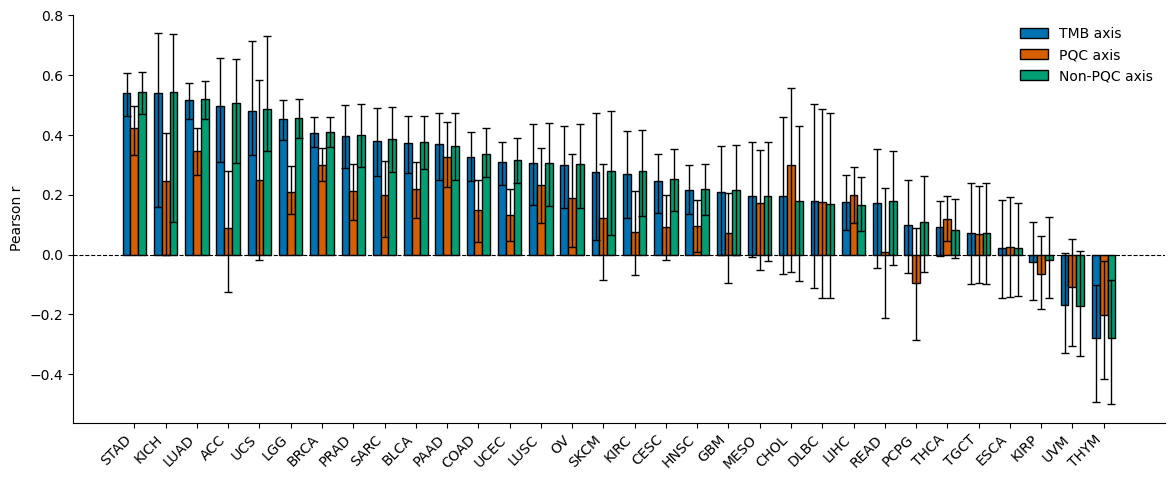

In [6]:
plot_corr_barplot(bs_corr_df, "2a_bs_corr_per_type")

## Per-score panels (recommended for text)

Use this when the claim is about **cross-cancer consistency within each score** (e.g. "TMB axis r > 0 in 29/32 cancer types").

- One panel per score; all cancer types shown together in that panel
- Horizontal point + 95% bootstrap CI (forest-style)
- Shared cancer order (TMB axis r, high → low); labels on the left panel only

The grouped bar chart above is better when comparing **the three scores within the same cancer**.

In [26]:
from matplotlib.gridspec import GridSpec

import sys

sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS

CI_COLOR = COLORS["light_gray"]


def plot_corr_by_score_panels(df, filename):
    """Forest-style panels: all cancer types together within each score."""
    order = (
        df[df["score"] == "TMB_axis_score"]
        .sort_values("r", ascending=False)["cancer_type"]
        .values
    )
    y = np.arange(len(order))

    x_min = df["ci_low"].min()
    x_max = df["ci_high"].max()
    pad = 0.02 * (x_max - x_min)

    fig = plt.figure(figsize=(10.5, 5.8))
    gs = GridSpec(1, 4, figure=fig, width_ratios=[0.38, 2.34, 2.34, 2.34], wspace=0.03)
    ax_y = fig.add_subplot(gs[0, 0])
    axes = [fig.add_subplot(gs[0, i], sharey=ax_y) for i in range(1, 4)]

    for ax, score in zip(axes, SCORES):
        df_sub = (
            df[df["score"] == score]
            .set_index("cancer_type")
            .reindex(order)
        )

        ax.errorbar(
            df_sub["r"],
            y,
            xerr=[df_sub["r"] - df_sub["ci_low"], df_sub["ci_high"] - df_sub["r"]],
            fmt="o",
            color=PALETTE[score],
            ecolor=CI_COLOR,
            elinewidth=0.8,
            capsize=1.5,
            markersize=3.5,
            markeredgecolor="black",
            markeredgewidth=0.4,
        )
        ax.axvline(0, color="black", linewidth=0.7, linestyle="--")
        ax.set_title(SCORE_LABELS[score], fontsize=10, loc="left", pad=4)
        ax.set_xlim(x_min - pad, x_max + pad)
        ax.tick_params(axis="y", left=False, labelleft=False)
        ax.tick_params(axis="x", labelsize=8)
        sns.despine(ax=ax, left=True, bottom=False)

    ax_y.set_yticks(y)
    ax_y.set_yticklabels(order, fontsize=7, ha="right")
    ax_y.set_ylim(-0.5, len(order) - 0.5)
    ax_y.invert_yaxis()
    ax_y.set_xticks([])
    ax_y.set_xlim(0, 1)
    ax_y.tick_params(axis="x", bottom=False)
    ax_y.tick_params(axis="y", length=0, pad=1, labelleft=False, labelright=True)
    ax_y.yaxis.set_ticks_position("right")
    for spine in ax_y.spines.values():
        spine.set_visible(False)

    fig.supxlabel("Pearson r (axis score vs log10 TMB)", fontsize=9, y=0.02)
    plt.savefig(f"{OUT_DIR}/{filename}.pdf", dpi=300, bbox_inches="tight", pad_inches=0.08)
    plt.show()

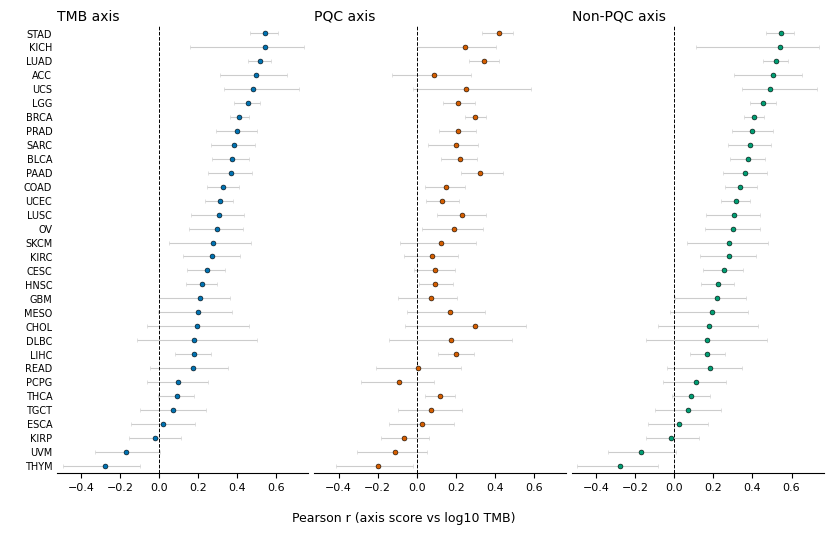

In [27]:
plot_corr_by_score_panels(bs_corr_df, "2a_bs_corr_per_type_by_score")

## Per-score panels (tight square boxes)

Same forest-style layout as above, but with **square data panels** (`set_box_aspect(1)`) and tighter margins. Useful when you want a more compact figure with equal panel geometry.

Tune `PANEL_SIZE` below to adjust overall scale.

In [ ]:
N_PANELS = 3
LABEL_WIDTH = 0.85
PANEL_SIZE = 3.2  # square data-panel side (inches)
FIG_WIDTH_TIGHT = LABEL_WIDTH + N_PANELS * PANEL_SIZE
FIG_HEIGHT_TIGHT = PANEL_SIZE


def _style_label_axis(ax_y, order, y):
    ax_y.set_yticks(y)
    ax_y.set_yticklabels(order, fontsize=7, ha="right")
    ax_y.set_ylim(-0.5, len(order) - 0.5)
    ax_y.invert_yaxis()
    ax_y.set_xticks([])
    ax_y.set_xlim(0, 1)
    ax_y.tick_params(axis="x", bottom=False)
    ax_y.tick_params(axis="y", length=0, pad=1, labelleft=False, labelright=True)
    ax_y.yaxis.set_ticks_position("right")
    for spine in ax_y.spines.values():
        spine.set_visible(False)


def plot_corr_by_score_panels_tight(df, filename):
    """Forest-style panels with square, tightly packed data boxes."""
    order = (
        df[df["score"] == "TMB_axis_score"]
        .sort_values("r", ascending=False)["cancer_type"]
        .values
    )
    y = np.arange(len(order))

    x_min = df["ci_low"].min()
    x_max = df["ci_high"].max()
    pad = 0.02 * (x_max - x_min)

    fig = plt.figure(figsize=(FIG_WIDTH_TIGHT, FIG_HEIGHT_TIGHT))
    gs = GridSpec(
        1,
        N_PANELS + 1,
        figure=fig,
        width_ratios=[LABEL_WIDTH / PANEL_SIZE] + [1.0] * N_PANELS,
        wspace=0.04,
    )
    ax_y = fig.add_subplot(gs[0, 0])
    axes = [fig.add_subplot(gs[0, i], sharey=ax_y) for i in range(1, N_PANELS + 1)]

    _style_label_axis(ax_y, order, y)

    for ax, score in zip(axes, SCORES):
        ax.set_box_aspect(1)
        df_sub = (
            df[df["score"] == score]
            .set_index("cancer_type")
            .reindex(order)
        )

        ax.errorbar(
            df_sub["r"],
            y,
            xerr=[df_sub["r"] - df_sub["ci_low"], df_sub["ci_high"] - df_sub["r"]],
            fmt="o",
            color=PALETTE[score],
            ecolor=CI_COLOR,
            elinewidth=0.8,
            capsize=1.5,
            markersize=3.5,
            markeredgecolor="black",
            markeredgewidth=0.4,
        )
        ax.axvline(0, color="black", linewidth=0.7, linestyle="--")
        ax.set_title(SCORE_LABELS[score], fontsize=9, loc="left", pad=2)
        ax.set_xlim(x_min - pad, x_max + pad)
        ax.tick_params(axis="y", left=False, labelleft=False)
        ax.tick_params(axis="x", labelsize=8)
        sns.despine(ax=ax, left=True, bottom=False)

    fig.supxlabel("Pearson r (axis score vs log10 TMB)", fontsize=9, y=0.01)
    fig.subplots_adjust(left=0.06, right=0.99, top=0.97, bottom=0.08)
    plt.savefig(f"{OUT_DIR}/{filename}.pdf", dpi=300, bbox_inches="tight", pad_inches=0.06)
    plt.show()


plot_corr_by_score_panels_tight(bs_corr_df, "2a_bs_corr_per_type_by_score_tight")